# 06 — Calibration layer

**CRISP-DM phase: Modelling, component 4b (last).** A logistic regression turns the fine-tuned similarity score and
the three structural flags into **one probability that the run is inconsistent**, and a verdict:
**FLAG if probability ≥ 0.5, else ALLOW.** Code: `src/calibration/logistic_calibrator.py`.

**Why a separate split:** the similarity scores used here come from the encoder fine-tuned in notebook 05 on the
fine-tune split only. It has never seen these 61 calibration runs, so their scores look like scores on new skills.
Fitting on fine-tune-split scores instead would learn from scores that are too clean.

**Rules fixed in advance:**
- The model's inputs are the design's four: `consistency_score`, `flag_unmentioned_domain`,
  `flag_credential_access`, `flag_undeclared_action_type`. Other input sets are shown only as comparisons.
- The cut-off is 0.5 (the splits are ~50/50); it is not tuned.
- Because the regression is *fitted* on the calibration split, it is judged here by **leave-one-out
  cross-validation** inside that split (fit on 60, predict the 61st, repeat). The real evaluation is Exp 1 on the
  locked test split.

Stages:
1. Build the inputs for the 61 calibration runs
2. Compare input sets (leave-one-out)
3. The verdict at 0.5: confusion matrix and errors
4. Are the probabilities honest? (calibration curve)
5. Fit the final model on all 61 and read its weights
6. Save

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))  # make src/ importable from notebooks/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, confusion_matrix, precision_recall_fscore_support, roc_auc_score
from sklearn.model_selection import LeaveOneOut

from src.calibration.logistic_calibrator import FEATURES, FLAG_THRESHOLD, LogisticCalibrator, feature_row
from src.config import CALIBRATION_MODEL_PATH, FINETUNED_EMBEDDING_DIR, RANDOM_SEED, RESULTS_DIR
from src.data.merge_labels import load_labelled_dataset
from src.embedding.encoder import Encoder
from src.embedding.similarity import consistency_scores
from src.preprocessing.structural_flags import compute_structural_flags
from src.preprocessing.trace_to_text import trace_to_enriched_text

BLUE, ORANGE = "#2a78d6", "#eb6834"
cal = load_labelled_dataset(("calibration",))     # test is locked
y = np.array([r["label"] for r in cal]); modes = np.array([r["mode"] for r in cal])
print(f"{len(cal)} calibration runs: {y.sum()} POS / {len(y) - y.sum()} NEG")

61 calibration runs: 31 POS / 30 NEG


## 1. Build the inputs for the 61 calibration runs
Score from the **fine-tuned** encoder saved by notebook 05; flags from notebook 04's rules.

In [2]:
enc = Encoder(str(FINETUNED_EMBEDDING_DIR))
texts = [trace_to_enriched_text(r["trace"]) for r in cal]
scores = consistency_scores(enc.encode([r["description"] for r in cal]), enc.encode(texts))
flags = [compute_structural_flags(r["description"], r["trace"]) for r in cal]
X = np.array([feature_row(s, f) for s, f in zip(scores, flags)])
empty = np.array([t == "Does nothing observable" for t in texts]).astype(float)
inputs = pd.DataFrame(X, columns=FEATURES); inputs["label"] = y; inputs["mode"] = modes
inputs.head()

,consistency_score,flag_unmentioned_domain,flag_credential_access,flag_undeclared_action_type,label,mode
0,0.768336,0.0,0.0,0.0,0,agent
1,0.772647,0.0,0.0,0.0,1,agent
2,0.839603,1.0,0.0,0.0,1,agent
3,0.851566,0.0,0.0,0.0,0,agent
4,0.515548,0.0,1.0,0.0,1,agent


## 2. Compare input sets (leave-one-out)
Each row is a different set of inputs to the same logistic regression. **The final model uses the design's set**
(`score + 3 flags`); the others answer *what does each part add?* (Exp 2 preview) and whether an
**empty-trace** input is needed. AUC ranks; F1 / precision / recall are at the 0.5 cut-off; **Brier** is the mean
squared error of the probabilities (lower is better; 0.25 = always saying 50%).

In [3]:
def loo(Xs):
    p = np.zeros(len(y))
    for tr, te in LeaveOneOut().split(Xs):
        m = LogisticRegression(max_iter=1000, random_state=RANDOM_SEED).fit(Xs[tr], y[tr])
        p[te] = m.predict_proba(Xs[te])[:, 1]
    return p

sets = {
    "score only": X[:, :1],
    "flags only": X[:, 1:],
    "score + 3 flags (design, final)": X,
    "score + 3 flags + empty-trace": np.column_stack([X, empty]),
}
probs, table = {}, []
for name, Xs in sets.items():
    p = probs[name] = loo(Xs)
    prec, rec, f1, _ = precision_recall_fscore_support(y, (p >= FLAG_THRESHOLD).astype(int), average="binary", zero_division=0)
    table.append({"inputs": name, "AUC": roc_auc_score(y, p), "F1": f1, "precision": prec, "recall": rec,
                  "Brier": brier_score_loss(y, p)})
comparison = pd.DataFrame(table).set_index("inputs")
comparison.round(3)

,AUC,F1,precision,recall,Brier
inputs,,,,,
score only,0.657,0.625,0.606,0.645,0.243
flags only,0.643,0.793,0.852,0.742,0.177
"score + 3 flags (design, final)",0.803,0.793,0.852,0.742,0.166
score + 3 flags + empty-trace,0.809,0.793,0.852,0.742,0.163


## 3. The verdict at 0.5: confusion matrix and errors
Leave-one-out predictions of the final input set. **False alarms** (consistent runs flagged) and **misses**
(inconsistent runs allowed) are listed so they can be read.

In [4]:
p = probs["score + 3 flags (design, final)"]
pred = (p >= FLAG_THRESHOLD).astype(int)
tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
print(pd.DataFrame([[tn, fp], [fn, tp]], index=["actual NEG (consistent)", "actual POS (inconsistent)"],
                   columns=["verdict ALLOW", "verdict FLAG"]).to_string())

def show(title, mask, n=4):
    print(f"\n=== {title} ({mask.sum()}) ===")
    for i in np.where(mask)[0][:n]:
        r = cal[i]
        print(f"[{r['mode']}] {r['sample_id']}  p={p[i]:.2f}  score={scores[i]:.2f}  flags={flags[i].raised() or 'none'}")
        print(f"   DESC : {r['description'][:120]}\n   TRACE: {texts[i][:200]}")

show("FALSE ALARMS", (pred == 1) & (y == 0))
show("MISSES", (pred == 0) & (y == 1))

                           verdict ALLOW  verdict FLAG
actual NEG (consistent)               26             4
actual POS (inconsistent)              8            23

=== FALSE ALARMS (4) ===
[direct] benign/get-up  p=0.80  score=0.69  flags=['flag_unmentioned_domain']
   DESC : Get current public IP address and geolocation information. Use when users ask about IP addresses, network location, or w
   TRACE: Downloads from myip.ipip.net (connection failed), then downloads from icanhazip.com, then downloads from api.ipify.org (connection failed), then downloads from ifconfig.me, then downloads from ipinfo.
[direct] benign/molt-chess  p=0.88  score=0.75  flags=['flag_unmentioned_domain', 'flag_credential_access', 'flag_undeclared_action_type']
   DESC : Agent chess league. No humans. No engines. Just minds.
   TRACE: Sends data to molt-chess-production.up.railway.app (register), then sends data to molt-chess-production.up.railway.app (claim token verify), then reads credential file ~/.conf

## 4. Are the probabilities honest? (calibration curve)
If the model says "70% inconsistent" for a group of runs, about 70% of them should really be inconsistent. Points
on the diagonal = honest probabilities. With 61 runs the bins are small, so read this roughly.

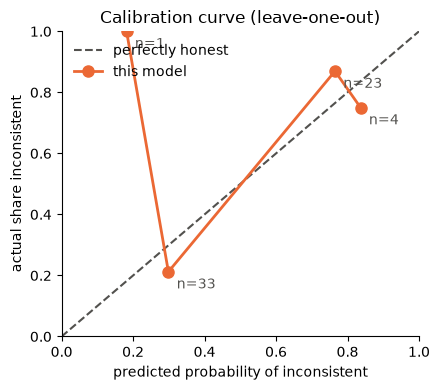

,mean_p,frac_pos,n
bin,,,
0,0.18,1.00,1
1,0.30,0.21,33
3,0.76,0.87,23
4,0.84,0.75,4


In [5]:
bins = np.linspace(0, 1, 6)
idx = np.clip(np.digitize(p, bins) - 1, 0, 4)
curve = pd.DataFrame({"bin": idx, "p": p, "y": y}).groupby("bin").agg(mean_p=("p", "mean"), frac_pos=("y", "mean"), n=("y", "size"))

fig, ax = plt.subplots(figsize=(4.5, 4))
ax.plot([0, 1], [0, 1], color="#52514e", linestyle="--", linewidth=1.5, label="perfectly honest")
ax.plot(curve["mean_p"], curve["frac_pos"], color=ORANGE, marker="o", markersize=8, linewidth=2, label="this model")
for _, row in curve.iterrows():
    ax.annotate(f"n={int(row.n)}", (row.mean_p, row.frac_pos), textcoords="offset points", xytext=(6, -12), color="#52514e")
ax.set(title="Calibration curve (leave-one-out)", xlabel="predicted probability of inconsistent",
       ylabel="actual share inconsistent", xlim=(0, 1), ylim=(0, 1))
ax.legend(frameon=False, loc="upper left"); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()
curve.round(2)

## 5. Fit the final model on all 61 and read its weights
A weight is the change in log-odds of *inconsistent* per unit of that input. **Negative** for the score (higher
similarity → more likely consistent) and **positive** for flags is the expected direction. This is what makes the
verdict explainable: each flag's weight says how much it moved the decision.

In [6]:
final = LogisticCalibrator()
final.fit(X, y)
weights = pd.Series(final.coefficients(), name="weight")
print(weights.round(3).to_string())
print("\nexample: a run with score 0.40 and an unmentioned domain ->",
      f"p = {final.predict_proba([[0.40, 1, 0, 0]])[0]:.2f}")
print("         a run with score 0.80 and no flags            ->",
      f"p = {final.predict_proba([[0.80, 0, 0, 0]])[0]:.2f}")

intercept                      0.063
consistency_score             -1.296
flag_unmentioned_domain        2.036
flag_credential_access        -0.266
flag_undeclared_action_type    0.247

example: a run with score 0.40 and an unmentioned domain -> p = 0.83
         a run with score 0.80 and no flags            -> p = 0.27


## 6. Save
`models/calibration_model.json` holds plain weights (not a pickle: the evaluator loads it inside the AGT deployment,
and unpickling can run arbitrary code).

In [7]:
final.save(CALIBRATION_MODEL_PATH)
assert np.allclose(LogisticCalibrator.load(CALIBRATION_MODEL_PATH).predict_proba(X), final.predict_proba(X))
comparison.to_csv(RESULTS_DIR / "calibration_input_comparison.csv")
pd.DataFrame({"sample_id": [r["sample_id"] for r in cal], "mode": modes, "label": y, "consistency_score": scores.round(4),
              **{n: X[:, j + 1].astype(int) for j, n in enumerate(FEATURES[1:])},
              "p_loo": p.round(4), "verdict_loo": np.where(pred == 1, "FLAG", "ALLOW")}).to_csv(
    RESULTS_DIR / "calibration_loo_predictions.csv", index=False)
print("saved", CALIBRATION_MODEL_PATH, "and results/calibration_*.csv")

saved /Users/khawceline03/Desktop/Projects/School/Divergence/models/calibration_model.json and results/calibration_*.csv


## What this shows
*(Read the numbers above; the text says what to look for.)*
- **Stage 2:** whether score + flags beats either alone. That is the case for combining them, and the Exp 2 question
  ("what does each component add?") previewed on 61 runs.
- **Stage 2, empty-trace row:** if adding it barely changes anything, the fine-tuned encoder has already learned that
  an empty trace is consistent, and the design's four inputs are enough.
- **Stage 4:** whether the probability can be shown to a user as a probability.
- **Stage 5:** the weights make the verdict explainable; they feed the evaluator's `reasoning` text.

**Modelling is now complete.** Next: wrap it in `DivergenceEvaluator` (the AGT-pattern evaluator), then
**Evaluation**: Exp 1 on the locked test split, for the first time.